# Propaga un diseño de incertidumbre con semilla

Nivel: 2. Requisitos previos: Nivel 1 de este tema y nivel 2 de conminución. Tiempo de lectura: 30 minutos.

## Objetivos

Ejecuta la función de incertidumbre OreFlow en un diseño pequeño con semilla, inspecciona la distribución simulada de recuperación y compara el punto nominal con el rango de muestras.

## Preparación

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

El pipeline OreFlow se importa desde `data-pipeline/`; este notebook nunca instala paquetes.

Configura las importaciones y registra versiones. Este paso hace reproducible la ejecución del método.

In [1]:
# Importa herramientas de análisis y registra sus versiones exactas.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resuelve el pipeline local desde la estructura relativa del repositorio.
repo = Path('../../../').resolve()
sys.path.insert(0, str(repo / 'data-pipeline'))
for package in ('numpy', 'scipy', 'pandas', 'matplotlib', 'nbclient', 'nbformat', 'ipykernel'):
    print(package, importlib.metadata.version(package))

numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Datos

Responsable: autores de OreFlow; escenario, límites del contrato y supuestos de incertidumbre en `data/derived/cases/copper_porphyry_soft.json`, `data/derived/contract/operating_contract.json` y `data/derived/benchmark.json`, licencia MIT del proyecto. Repositorio: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Método

El método de producción transforma un diseño hipercubo latino determinista mediante `perturbed` y `_evaluate` de OreFlow, que llaman al solver del proceso. Los estados estacionarios rechazados se cuentan; no se convierten silenciosamente en mediciones. Esta lección usa 32 corridas para inspección; el registro comprometido usa el tamaño de muestra de producción.

Ejecuta el método de incertidumbre del producto con semilla fija y una muestra pequeña para un experimento rápido y reproducible.

In [2]:
from pipeline.cases.catalog import CASES
from pipeline.methods.uncertainty import uncertainty

# Paso ejecutable del método OreFlow explicado en la celda anterior.
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
experiment = uncertainty(case, case.nominal, samples=32, seed=20261027)
print('samples:', experiment['samples'], '| seed:', experiment['seed'], '| solved:', len(experiment['solved']))
print('refused:', experiment['refused'])
print('input half-widths:', experiment['inputs'])

samples: 32 | seed: 20261027 | solved: 32
refused: {}
input half-widths: {'work_index': {'half_width': 0.2}, 'head_grade': {'half_width': 0.2}, 'liberation_size': {'half_width': 0.25}, 'floatability': {'half_width': 0.25}}


Grafica las recuperaciones resueltas y marca el resultado nominal del motor. El histograma depende de este escenario y dominio de entradas.

P05/P50/P95: [89.47438797 91.87000065 93.45258867]


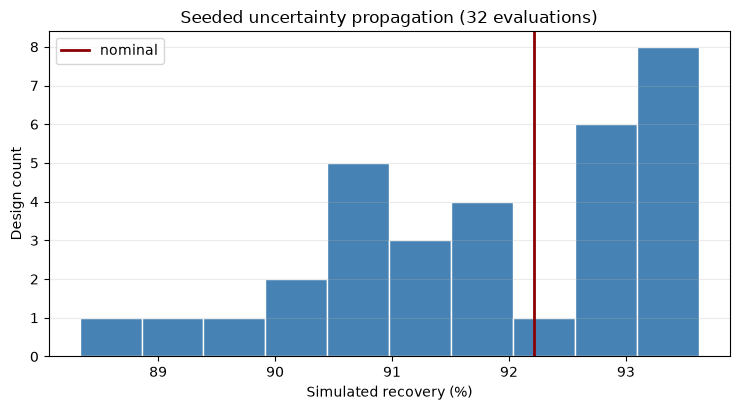

In [3]:
# Grafica las recuperaciones resueltas y marca el resultado nominal del motor.
recovery = np.asarray(experiment['outputs']['recovery_pct']['values'], dtype=float)
nominal = case.nominal
from pipeline.engine.circuit import simulate
nominal_result = simulate(case.ore, case.plant, nominal)
nominal_recovery = nominal_result.metrics['recovery_pct']
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.hist(recovery, bins=10, color='steelblue', edgecolor='white')
ax.axvline(nominal_recovery, color='darkred', linewidth=2, label='nominal')
ax.set(xlabel='Simulated recovery (%)', ylabel='Design count', title='Seeded uncertainty propagation (32 evaluations)')
ax.grid(True, axis='y', alpha=.25); ax.legend(); fig.tight_layout()
print('P05/P50/P95:', np.quantile(recovery, [0.05, 0.5, 0.95]))

Verifica reproducibilidad repitiendo la misma semilla y comparando exactamente el diseño y las recuperaciones.

In [4]:
# Verifica reproducibilidad repitiendo la misma semilla y comparando exactamente el diseño y las recuperaciones.
repeat = uncertainty(case, case.nominal, samples=32, seed=20261027)
print('design identical:', experiment['design'] == repeat['design'])
print('recoveries identical:', experiment['outputs']['recovery_pct'] == repeat['outputs']['recovery_pct'])
print('constraint probabilities:', experiment['probabilities'])

design identical: True
recoveries identical: True
constraint probabilities: {'grade_meets_spec': 1.0, 'power_within_installed': 0.8125, 'water_within_capacity': 1.0, 'all_constraints': 0.8125}


## Resultados

El histograma muestra 32 salidas generadas por el motor bajo los factores elegidos. Repetir la semilla confirma determinismo. La muestra es menor que el registro comprometido, por lo que sus cuantiles y probabilidades tienen más ruido y no son límites de confianza de planta.

## Resumen

Ejecutaste una propagación determinista de incertidumbre por el motor de producción y comprobaste su dependencia del diseño finito elegido. La simulación reproducible sigue condicionada por sus supuestos.

## Referencias

- https://doi.org/10.1080/00401706.1979.10489755